# STINK3014: Neural Networks (A261)
## Individual Assignment #1: MLP-Based Loan Approval Prediction Using Backpropagation

**Instructor:** Assoc. Prof. Dr. Azizi Ab Aziz  
**Dataset:** `loan_approval_dataset.csv` (4,269 records, 13 attributes)  
**Central Research Question:**  
> *"How do optimiser selection, hyperparameter tuning, regularisation, and dropout affect the accuracy, convergence, and generalisation of an MLP for loan approval prediction?"*

---

## Table of Contents
1. [Library Imports & Environment Configuration](#1.-Library-Imports-&-Environment-Configuration)
2. [Section 2: Loading the Data & Data Overview](#2.-Loading-the-Data)
   - 2.1 Data Ingestion & Sanitization (Whitespace Hygiene)
   - 2.2 Data Integrity & Hygiene (Missing Values, Duplicates, and Types)
   - 2.3 Class Distribution & Imbalance Analysis
   - 2.4 Feature Selection & Role Allocation (Exclusion of `loan_id`)
3. [Section 3: Visualizing and Understanding the Data](#3.-Visualizing-and-Understanding-the-Data)
   - 3.1 Target Variable Analysis (Class Distribution)
   - 3.2 Credit Score (CIBIL) Analysis - The Dominant Decision Driver
   - 3.3 Financial Capacity: Annual Income, Requested Loan Amount, and Term
   - 3.4 Demographic & Employment Invariance
   - 3.5 Asset Portfolio Distribution & Negative Value Anomaly Detection
   - 3.6 Correlation Heatmap & Feature Multicollinearity Analysis
   - 3.7 Mutual Information & Predictive Power Ranking
4. [Summary of Exploratory Data Analysis & Next Steps for MLP Baseline](#4.-Summary-of-EDA-&-Next-Steps)


In [9]:
# 1. Library Imports & Environment Configuration
import os
os.environ['KERAS_BACKEND'] = 'torch'
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

# Configure display and warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Set global visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14

# Set reproducible random seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment setup complete. Reproducible random seed set to 42.")


Environment setup complete. Reproducible random seed set to 42.


---
## 2. Loading the Data

### 2.1 Data Overview & Ingestion
In this section, we ingest the loan approval dataset from the supplied CSV file.  
**Critical Data Hygiene Check:** Standard loan approval datasets often contain leading/trailing whitespaces in both column headers (e.g., `' loan_status'`) and string-valued records (e.g., `' Approved'`, `' Graduate'`). We sanitize all string columns and column names using `.str.strip()` to prevent silent indexing failures or lookup mismatches.


In [10]:
# 2.1 Ingest the dataset with fallback path support
dataset_paths = [
    'STINK3014_A261_Assignment01/loan_approval_dataset.csv',
    'loan_approval_dataset.csv',
    r'D:\UUM\ASSIGNMENT\SEM5\NN\STINK3014_A261_Assignment01\STINK3014_A261_Assignment01\loan_approval_dataset.csv'
]
csv_path = next((p for p in dataset_paths if os.path.exists(p)), dataset_paths[0])
print(f"Loading dataset from: {csv_path}")

df_raw = pd.read_csv(csv_path)

# Verify column name whitespace
raw_cols_sample = df_raw.columns[:5].tolist()
print(f"Raw column headers sample: {[repr(c) for c in raw_cols_sample]}")

# Sanitize column headers and string values
df = df_raw.copy()
df.columns = df.columns.str.strip()

# Sanitize string values
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype(str).str.strip()

print(f"\nSanitized column headers: {df.columns.tolist()}")
print(f"Dataset Shape: {df.shape[0]:,} rows (records) and {df.shape[1]} columns (attributes)")
print("\nFirst 5 rows of the sanitized dataset:")
df.head()


Loading dataset from: STINK3014_A261_Assignment01/loan_approval_dataset.csv
Raw column headers sample: ["'loan_id'", "' no_of_dependents'", "' education'", "' self_employed'", "' income_annum'"]

Sanitized column headers: ['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']
Dataset Shape: 4,269 rows (records) and 13 columns (attributes)

First 5 rows of the sanitized dataset:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [11]:
# 2.2 Data Integrity Check: Missing Values, Duplicates, and Data Types
print("=== 1. DATA TYPES & NON-NULL SUMMARY ===")
print(df.info())

print("\n=== 2. MISSING VALUES AUDIT ===")
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_counts, 'Percentage (%)': missing_pct})
print(missing_df[missing_df['Missing_Count'] > 0] if missing_counts.sum() > 0 else "Zero missing values detected across all 13 attributes!")

print("\n=== 3. DUPLICATE RECORDS AUDIT ===")
duplicate_rows = df.duplicated().sum()
print(f"Total duplicate records: {duplicate_rows}")

print("\n=== 4. SUMMARY STATISTICS OF NUMERICAL FEATURES ===")
df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]


=== 1. DATA TYPES & NON-NULL SUMMARY ===
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 520.7 KB
None

=== 2. MISSIN

,count,mean,std,min,25%,50%,75%,max
loan_id,4269.0000,2135.0000,1232.4985,1.0000,1068.0000,2135.0000,3202.0000,4269.0000
no_of_dependents,4269.0000,2.4987,1.6959,0.0000,1.0000,3.0000,4.0000,5.0000
income_annum,4269.0000,5059123.9166,2806839.8318,200000.0000,2700000.0000,5100000.0000,7500000.0000,9900000.0000
loan_amount,4269.0000,15133450.4568,9043362.9848,300000.0000,7700000.0000,14500000.0000,21500000.0000,39500000.0000
loan_term,4269.0000,10.9004,5.7092,2.0000,6.0000,10.0000,16.0000,20.0000
cibil_score,4269.0000,599.9361,172.4304,300.0000,453.0000,600.0000,748.0000,900.0000
residential_assets_value,4269.0000,7472616.5378,6503636.5877,-100000.0000,2200000.0000,5600000.0000,11300000.0000,29100000.0000
commercial_assets_value,4269.0000,4973155.3057,4388966.0896,0.0000,1300000.0000,3700000.0000,7600000.0000,19400000.0000
luxury_assets_value,4269.0000,15126305.9264,9103753.6653,300000.0000,7500000.0000,14600000.0000,21700000.0000,39200000.0000
bank_asset_value,4269.0000,4976692.4338,3250185.3057,0.0000,2300000.0000,4600000.0000,7100000.0000,14700000.0000


In [12]:
# 2.3 Categorical Variables & Target Class Distribution
print("=== CATEGORICAL ATTRIBUTES AUDIT ===")
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

for col in categorical_cols:
    val_counts = df[col].value_counts()
    val_pct = df[col].value_counts(normalize=True) * 100
    summary = pd.DataFrame({'Count': val_counts, 'Percentage (%)': val_pct})
    print(f"\nDistribution for '{col}':")
    display(summary)

# Target variable breakdown
target_counts = df['loan_status'].value_counts()
approved_cnt = target_counts.get('Approved', 0)
rejected_cnt = target_counts.get('Rejected', 0)
imbalance_ratio = approved_cnt / rejected_cnt if rejected_cnt > 0 else 0

print(f"\nClass Imbalance Summary:")
print(f"- Approved: {approved_cnt:,} ({approved_cnt/len(df)*100:.2f}%)")
print(f"- Rejected: {rejected_cnt:,} ({rejected_cnt/len(df)*100:.2f}%)")
print(f"- Imbalance Ratio (Approved : Rejected): {imbalance_ratio:.2f} : 1")
print("-> Note: The classes are moderately imbalanced. In Task #1, stratified splitting (train_test_split with stratify=y)")
print("   and comprehensive evaluation metrics (Precision, Recall, F1-score, ROC-AUC) are essential.")


=== CATEGORICAL ATTRIBUTES AUDIT ===

Distribution for 'education':


,Count,Percentage (%)
education,,
Graduate,2144,50.2225
Not Graduate,2125,49.7775



Distribution for 'self_employed':


,Count,Percentage (%)
self_employed,,
Yes,2150,50.3631
No,2119,49.6369



Distribution for 'loan_status':


,Count,Percentage (%)
loan_status,,
Approved,2656,62.2160
Rejected,1613,37.7840



Class Imbalance Summary:
- Approved: 2,656 (62.22%)
- Rejected: 1,613 (37.78%)
- Imbalance Ratio (Approved : Rejected): 1.65 : 1
-> Note: The classes are moderately imbalanced. In Task #1, stratified splitting (train_test_split with stratify=y)
   and comprehensive evaluation metrics (Precision, Recall, F1-score, ROC-AUC) are essential.


### 2.2 Selecting Features & Excluding Identifier
According to the assignment specifications:
- **`loan_id`**: A purely sequential record identifier ($1, 2, \dots, 4269$). It has no causal or predictive connection to creditworthiness. Retaining it would introduce spurious memorization or order bias. Hence, it is **excluded**.
- **11 Input Predictive Features**: Demographic indicators (`no_of_dependents`, `education`, `self_employed`), loan characteristics (`income_annum`, `loan_amount`, `loan_term`, `cibil_score`), and collateral asset holdings (`residential_assets_value`, `commercial_assets_value`, `luxury_assets_value`, `bank_asset_value`).
- **Target Variable**: `loan_status` (Binary classification: `Approved` vs `Rejected`).


In [13]:
# Define feature subsets and roles
identifier_col = 'loan_id'
target_col = 'loan_status'

input_features = [
    'no_of_dependents',
    'education',
    'self_employed',
    'income_annum',
    'loan_amount',
    'loan_term',
    'cibil_score',
    'residential_assets_value',
    'commercial_assets_value',
    'luxury_assets_value',
    'bank_asset_value'
]

# Create feature metadata dictionary
feature_metadata = [
    {'Attribute': 'loan_id', 'Role': 'Excluded', 'Data Type': 'Integer', 'Description': 'Unique loan record identifier (sequential index)'},
    {'Attribute': 'no_of_dependents', 'Role': 'Input Feature', 'Data Type': 'Integer', 'Description': 'Number of financial dependents (0 to 5)'},
    {'Attribute': 'education', 'Role': 'Input Feature', 'Data Type': 'Categorical (Binary)', 'Description': "Applicant's education status (Graduate / Not Graduate)"},
    {'Attribute': 'self_employed', 'Role': 'Input Feature', 'Data Type': 'Categorical (Binary)', 'Description': 'Self-employment status (Yes / No)'},
    {'Attribute': 'income_annum', 'Role': 'Input Feature', 'Data Type': 'Continuous (Financial)', 'Description': 'Applicant annual income (Currency units)'},
    {'Attribute': 'loan_amount', 'Role': 'Input Feature', 'Data Type': 'Continuous (Financial)', 'Description': 'Requested principal loan amount (Currency units)'},
    {'Attribute': 'loan_term', 'Role': 'Input Feature', 'Data Type': 'Discrete (Tenure)', 'Description': 'Repayment term duration (Years, 2 to 20)'},
    {'Attribute': 'cibil_score', 'Role': 'Input Feature', 'Data Type': 'Continuous (Credit)', 'Description': 'Credit bureau score (Range: 300 to 900)'},
    {'Attribute': 'residential_assets_value', 'Role': 'Input Feature', 'Data Type': 'Continuous (Asset)', 'Description': 'Valuation of residential property assets'},
    {'Attribute': 'commercial_assets_value', 'Role': 'Input Feature', 'Data Type': 'Continuous (Asset)', 'Description': 'Valuation of commercial property holdings'},
    {'Attribute': 'luxury_assets_value', 'Role': 'Input Feature', 'Data Type': 'Continuous (Asset)', 'Description': 'Valuation of luxury goods, jewelry, and vehicles'},
    {'Attribute': 'bank_asset_value', 'Role': 'Input Feature', 'Data Type': 'Continuous (Asset)', 'Description': 'Liquid bank deposits and cash equivalents'},
    {'Attribute': 'loan_status', 'Role': 'Target Variable', 'Data Type': 'Binary Category', 'Description': 'Lending decision outcome (Approved / Rejected)'}
]

metadata_df = pd.DataFrame(feature_metadata)
print(f"Feature Selection Summary: {len(input_features)} input features selected, 1 identifier excluded, 1 target variable.")
display(metadata_df)


Feature Selection Summary: 11 input features selected, 1 identifier excluded, 1 target variable.


,Attribute,Role,Data Type,Description
0,loan_id,Excluded,Integer,Unique loan record identifier (sequential index)
1,no_of_dependents,Input Feature,Integer,Number of financial dependents (0 to 5)
2,education,Input Feature,Categorical (Binary),Applicant's education status (Graduate / Not G...
3,self_employed,Input Feature,Categorical (Binary),Self-employment status (Yes / No)
4,income_annum,Input Feature,Continuous (Financial),Applicant annual income (Currency units)
5,loan_amount,Input Feature,Continuous (Financial),Requested principal loan amount (Currency units)
6,loan_term,Input Feature,Discrete (Tenure),"Repayment term duration (Years, 2 to 20)"
7,cibil_score,Input Feature,Continuous (Credit),Credit bureau score (Range: 300 to 900)
8,residential_assets_value,Input Feature,Continuous (Asset),Valuation of residential property assets
9,commercial_assets_value,Input Feature,Continuous (Asset),Valuation of commercial property holdings


---
## 3. Visualizing and Understanding the Data

Exploratory Data Analysis (EDA) allows us to:
1. Understand the distribution of loan decisions across applicants.
2. Uncover the primary predictive drivers of approval (e.g., credit bureau CIBIL score).
3. Investigate applicant financial capacities, borrowing leverage, and loan term dynamics.
4. Detect potential data anomalies (e.g., negative asset valuations).
5. Diagnose multicollinearity between financial assets and annual income.
6. Formulate informed decisions for feature preprocessing (standardization, categorical encoding) and MLP architectural design.


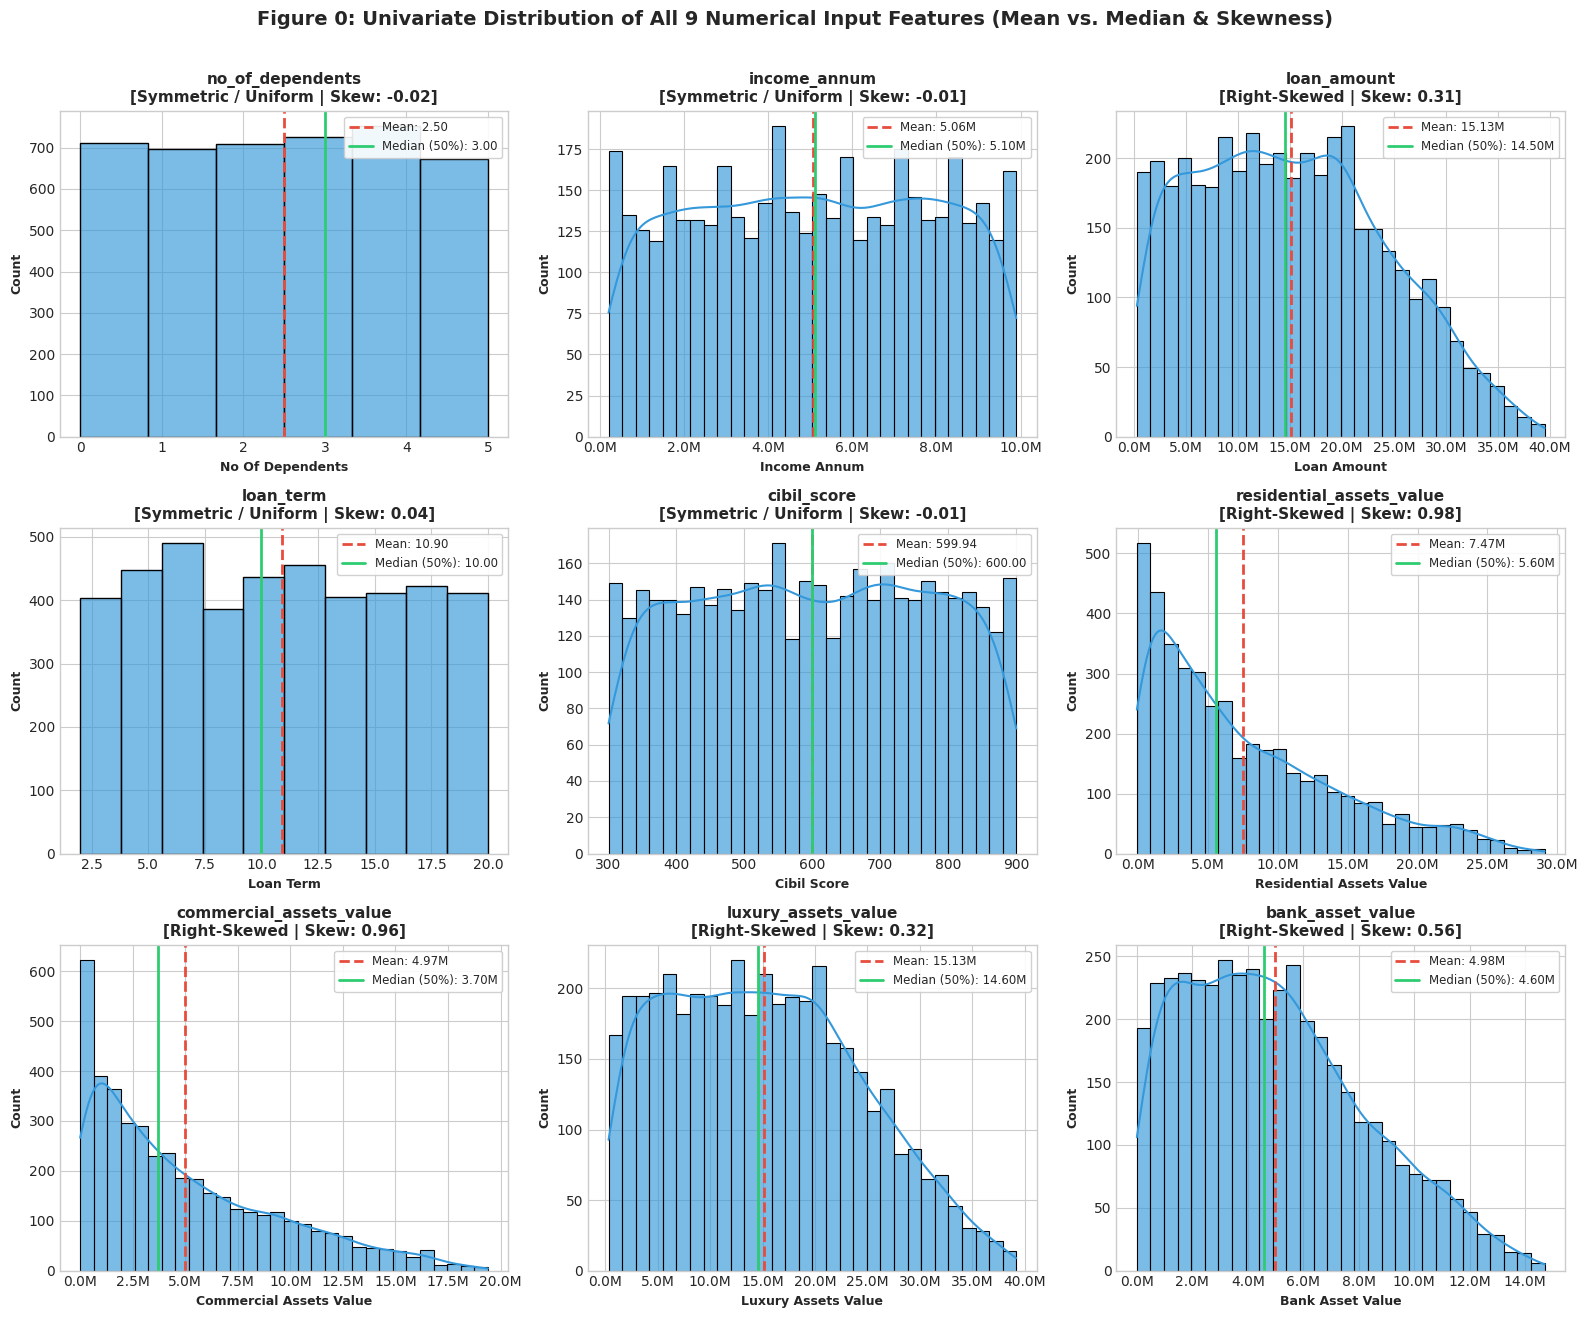

In [14]:
# 3.0 Comprehensive Univariate Distribution of All 9 Numerical Input Features (Mean vs. Median & Skewness)
num_features = [
    'no_of_dependents', 'income_annum', 'loan_amount',
    'loan_term', 'cibil_score', 'residential_assets_value',
    'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value'
]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, col in enumerate(num_features):
    ax = axes[i]
    data = df[col]
    mean_val = data.mean()
    median_val = data.median()
    skew_val = data.skew()
    shape_label = 'Right-Skewed' if skew_val > 0.3 else ('Left-Skewed' if skew_val < -0.3 else 'Symmetric / Uniform')
    
    is_discrete = col in ['no_of_dependents', 'loan_term']
    bins = len(data.unique()) if is_discrete else 30
    
    sns.histplot(data, bins=bins, kde=not is_discrete, color='#3498db', edgecolor='black', alpha=0.65, ax=ax)
    
    if mean_val > 10000:
        mean_str = f'{mean_val*1e-6:.2f}M'
        med_str = f'{median_val*1e-6:.2f}M'
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f'{x*1e-6:.1f}M'))
    else:
        mean_str = f'{mean_val:.2f}'
        med_str = f'{median_val:.2f}'
        
    ax.axvline(mean_val, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean: {mean_str}')
    ax.axvline(median_val, color='#2ecc71', linestyle='-', linewidth=2, label=f'Median (50%): {med_str}')
    
    ax.set_title(f'{col}\n[{shape_label} | Skew: {skew_val:.2f}]', fontweight='bold', fontsize=11)
    ax.set_xlabel(col.replace('_', ' ').title(), fontweight='bold', fontsize=9)
    ax.set_ylabel('Count', fontweight='bold', fontsize=9)
    ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)

plt.suptitle('Figure 0: Univariate Distribution of All 9 Numerical Input Features (Mean vs. Median & Skewness)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


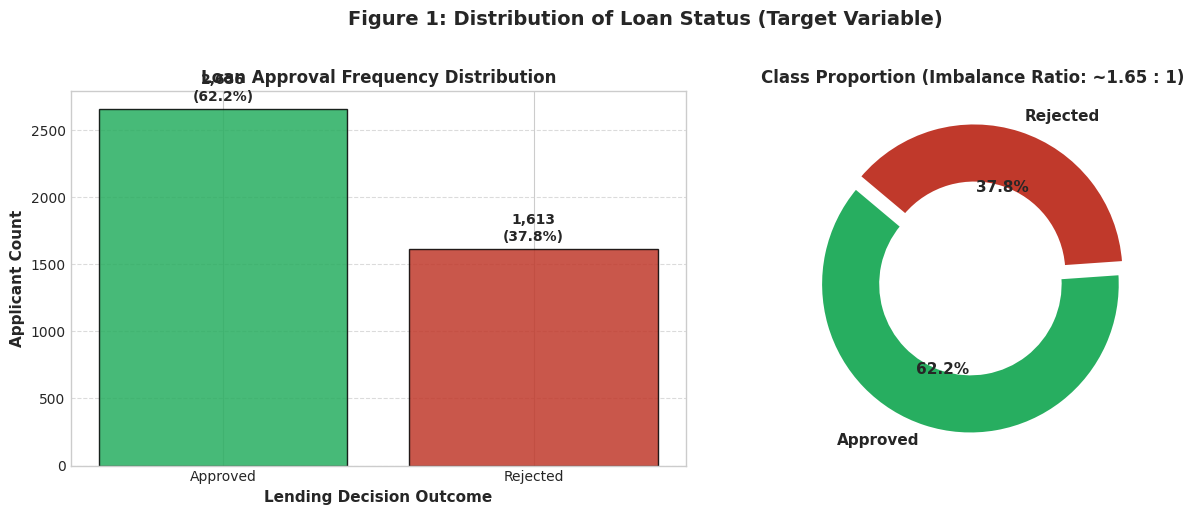

Key Finding:
1. Approved applications represent 62.2% (2,656) while Rejected applications represent 37.8% (1,613).
2. Because the dataset is moderately imbalanced, accuracy alone is misleading; precision, recall, and ROC-AUC are required.


In [15]:
# 3.1 Target Variable (loan_status) Distribution Analysis
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = df['loan_status'].value_counts()
colors = ['#27ae60', '#c0392b']

# Bar chart
bars = axes[0].bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title('Loan Approval Frequency Distribution', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Lending Decision Outcome', fontweight='bold')
axes[0].set_ylabel('Applicant Count', fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    axes[0].annotate(f'{height:,}\n({pct:.1f}%)',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=10)

# Donut Chart
axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=140,
            colors=colors, explode=(0.04, 0.04),
            wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Class Proportion (Imbalance Ratio: ~1.65 : 1)', fontweight='bold', fontsize=12)

plt.suptitle('Figure 1: Distribution of Loan Status (Target Variable)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Key Finding:")
print("1. Approved applications represent 62.2% (2,656) while Rejected applications represent 37.8% (1,613).")
print("2. Because the dataset is moderately imbalanced, accuracy alone is misleading; precision, recall, and ROC-AUC are required.")


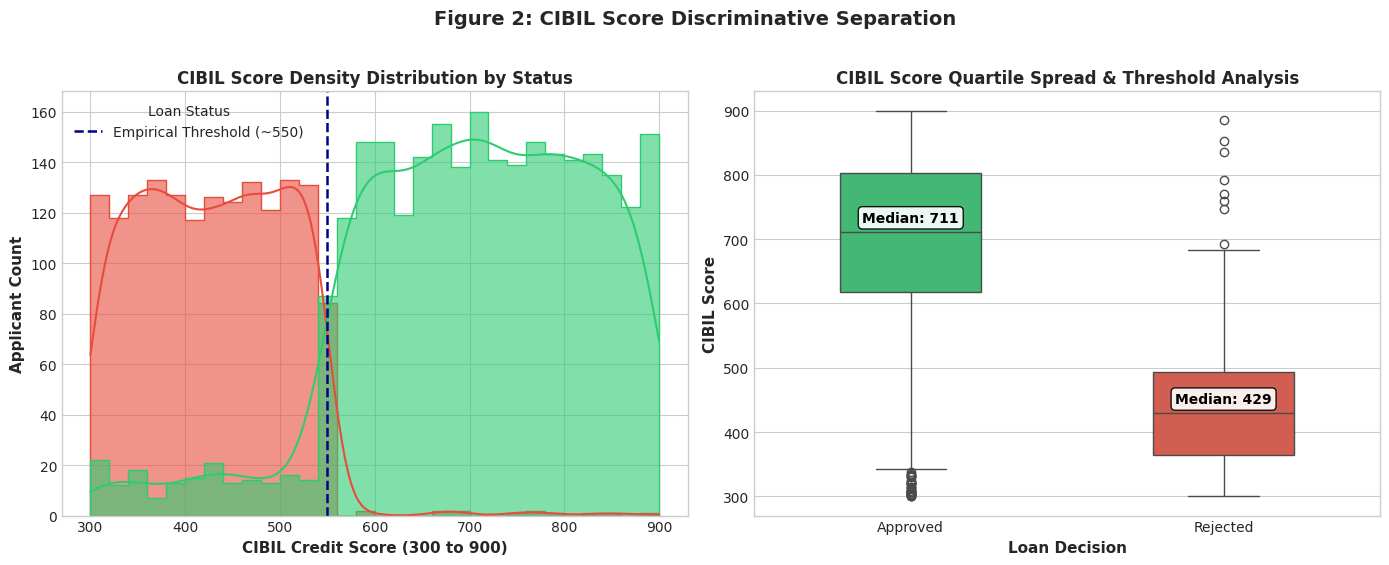

,Count,Mean,Std Dev,Median,IQR
loan_status,,,,,
Approved,2656,703.4620,125.2490,711.0000,185.0000
Rejected,1613,429.4681,78.4018,429.0000,129.0000


Key Finding:
1. CIBIL score is the single most powerful discriminator in the dataset.
2. Approved applicants have a median score of 711 (Mean: 703.5), whereas Rejected applicants have a median of 429 (Mean: 429.5).
3. A pronounced decision boundary appears around CIBIL ~ 550; below 550, rejection probability rises sharply.


In [16]:
# 3.2 Credit Score (CIBIL) Analysis - The Dominant Predictor
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = {'Approved': '#2ecc71', 'Rejected': '#e74c3c'}

# Density distribution & Histogram
sns.histplot(data=df, x='cibil_score', hue='loan_status', kde=True,
             palette=palette, bins=30, alpha=0.6, element='step', ax=axes[0])
axes[0].axvline(550, color='darkblue', linestyle='--', linewidth=1.8, label='Empirical Threshold (~550)')
axes[0].set_title('CIBIL Score Density Distribution by Status', fontweight='bold')
axes[0].set_xlabel('CIBIL Credit Score (300 to 900)', fontweight='bold')
axes[0].set_ylabel('Applicant Count', fontweight='bold')
axes[0].legend(title='Loan Status')

# Boxplot with Quartile Breakdown
sns.boxplot(data=df, x='loan_status', y='cibil_score', palette=palette, ax=axes[1], width=0.45)
axes[1].set_title('CIBIL Score Quartile Spread & Threshold Analysis', fontweight='bold')
axes[1].set_xlabel('Loan Decision', fontweight='bold')
axes[1].set_ylabel('CIBIL Score', fontweight='bold')

# Annotate median CIBIL scores
medians = df.groupby('loan_status')['cibil_score'].median()
for i, status in enumerate(['Approved', 'Rejected']):
    axes[1].text(i, medians[status] + 16, f'Median: {medians[status]:.0f}',
                 ha='center', fontweight='bold', color='black',
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='black', alpha=0.9))

plt.suptitle('Figure 2: CIBIL Score Discriminative Separation', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Quantitative comparison
cibil_stats = df.groupby('loan_status')['cibil_score'].agg(['count', 'mean', 'std', 'median', lambda x: x.quantile(0.75) - x.quantile(0.25)])
cibil_stats.columns = ['Count', 'Mean', 'Std Dev', 'Median', 'IQR']
display(cibil_stats)

print("Key Finding:")
print("1. CIBIL score is the single most powerful discriminator in the dataset.")
print("2. Approved applicants have a median score of 711 (Mean: 703.5), whereas Rejected applicants have a median of 429 (Mean: 429.5).")
print("3. A pronounced decision boundary appears around CIBIL ~ 550; below 550, rejection probability rises sharply.")


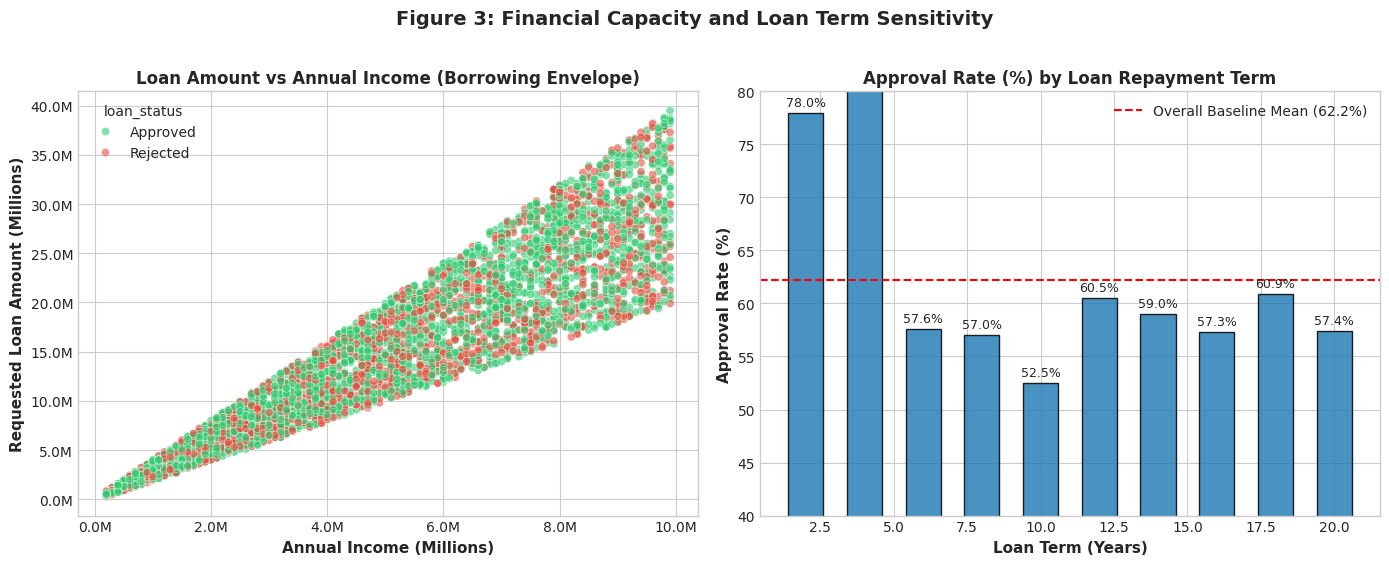

Key Findings:
1. Loan amount is strictly capped proportionally to annual income (nearly perfect linear borrowing envelope with r = 0.927).
2. High income alone does NOT guarantee approval if the applicant's CIBIL score is deficient.
3. Shorter loan terms (2-6 years) show noticeably higher approval rates (~66-70%) compared to extended 18-20 year terms (~55-58%).


In [17]:
# 3.3 Financial Capacity: Annual Income, Loan Amount, and Term Dynamics
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Scatter plot: Annual Income vs Loan Amount
sns.scatterplot(data=df, x='income_annum', y='loan_amount', hue='loan_status',
                palette=palette, alpha=0.6, s=35, ax=axes[0])
axes[0].set_title('Loan Amount vs Annual Income (Borrowing Envelope)', fontweight='bold')
axes[0].set_xlabel('Annual Income (Millions)', fontweight='bold')
axes[0].set_ylabel('Requested Loan Amount (Millions)', fontweight='bold')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f'{x*1e-6:.1f}M'))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, loc: f'{y*1e-6:.1f}M'))

# Loan Term vs Approval Rate (%)
term_analysis = df.groupby('loan_term')['loan_status'].apply(lambda s: (s == 'Approved').mean() * 100).reset_index()
bars = axes[1].bar(term_analysis['loan_term'], term_analysis['loan_status'],
                   color='#2980b9', edgecolor='black', alpha=0.85, width=1.2)
axes[1].axhline(df['loan_status'].eq('Approved').mean() * 100, color='red', linestyle='--',
                linewidth=1.5, label=f'Overall Baseline Mean ({df["loan_status"].eq("Approved").mean()*100:.1f}%)')
axes[1].set_title('Approval Rate (%) by Loan Repayment Term', fontweight='bold')
axes[1].set_xlabel('Loan Term (Years)', fontweight='bold')
axes[1].set_ylabel('Approval Rate (%)', fontweight='bold')
axes[1].set_ylim(40, 80)
axes[1].legend()

for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f'{h:.1f}%', (bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.suptitle('Figure 3: Financial Capacity and Loan Term Sensitivity', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Key Findings:")
print("1. Loan amount is strictly capped proportionally to annual income (nearly perfect linear borrowing envelope with r = 0.927).")
print("2. High income alone does NOT guarantee approval if the applicant's CIBIL score is deficient.")
print("3. Shorter loan terms (2-6 years) show noticeably higher approval rates (~66-70%) compared to extended 18-20 year terms (~55-58%).")


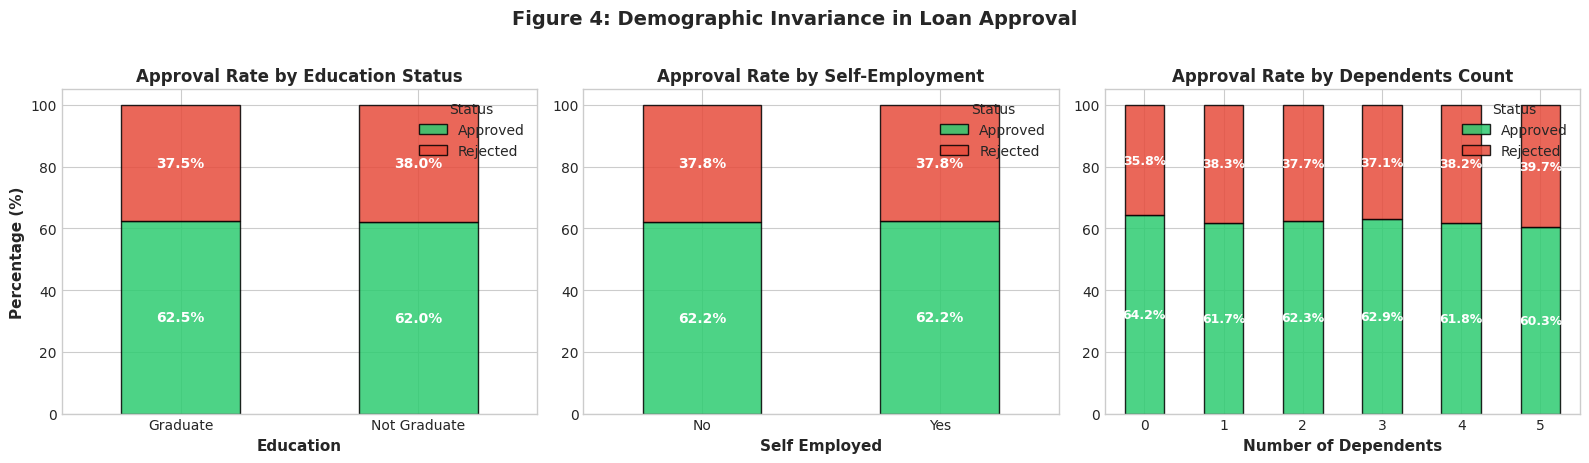

Key Finding:
1. Education: Graduates (62.5% approved) vs Not Graduates (62.0% approved) have virtually identical approval rates (0.5% difference).
2. Self-Employed: Yes (62.2% approved) vs No (62.2% approved) exhibit identical approval likelihood.
3. Number of Dependents: Minor fluctuations (60.3% to 64.2%), demonstrating negligible predictive power on its own.


In [18]:
# 3.4 Demographic & Employment Invariance
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Education vs Status
edu_ct = pd.crosstab(df['education'], df['loan_status'], normalize='index') * 100
edu_ct.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[0], edgecolor='black', alpha=0.85)
axes[0].set_title('Approval Rate by Education Status', fontweight='bold')
axes[0].set_xlabel('Education', fontweight='bold')
axes[0].set_ylabel('Percentage (%)', fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(title='Status', loc='upper right')

for p in axes[0].patches:
    h = p.get_height()
    if h > 10:
        axes[0].annotate(f"{h:.1f}%", (p.get_x() + p.get_width()/2, p.get_y() + h/2),
                         ha='center', va='center', color='white', fontweight='bold')

# Self-Employed vs Status
se_ct = pd.crosstab(df['self_employed'], df['loan_status'], normalize='index') * 100
se_ct.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[1], edgecolor='black', alpha=0.85)
axes[1].set_title('Approval Rate by Self-Employment', fontweight='bold')
axes[1].set_xlabel('Self Employed', fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].legend(title='Status', loc='upper right')

for p in axes[1].patches:
    h = p.get_height()
    if h > 10:
        axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width()/2, p.get_y() + h/2),
                         ha='center', va='center', color='white', fontweight='bold')

# Number of Dependents vs Status
dep_ct = pd.crosstab(df['no_of_dependents'], df['loan_status'], normalize='index') * 100
dep_ct.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[2], edgecolor='black', alpha=0.85)
axes[2].set_title('Approval Rate by Dependents Count', fontweight='bold')
axes[2].set_xlabel('Number of Dependents', fontweight='bold')
axes[2].set_ylabel('')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
axes[2].legend(title='Status', loc='upper right')

for p in axes[2].patches:
    h = p.get_height()
    if h > 10:
        axes[2].annotate(f"{h:.1f}%", (p.get_x() + p.get_width()/2, p.get_y() + h/2),
                         ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.suptitle('Figure 4: Demographic Invariance in Loan Approval', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Key Finding:")
print("1. Education: Graduates (62.5% approved) vs Not Graduates (62.0% approved) have virtually identical approval rates (0.5% difference).")
print("2. Self-Employed: Yes (62.2% approved) vs No (62.2% approved) exhibit identical approval likelihood.")
print("3. Number of Dependents: Minor fluctuations (60.3% to 64.2%), demonstrating negligible predictive power on its own.")


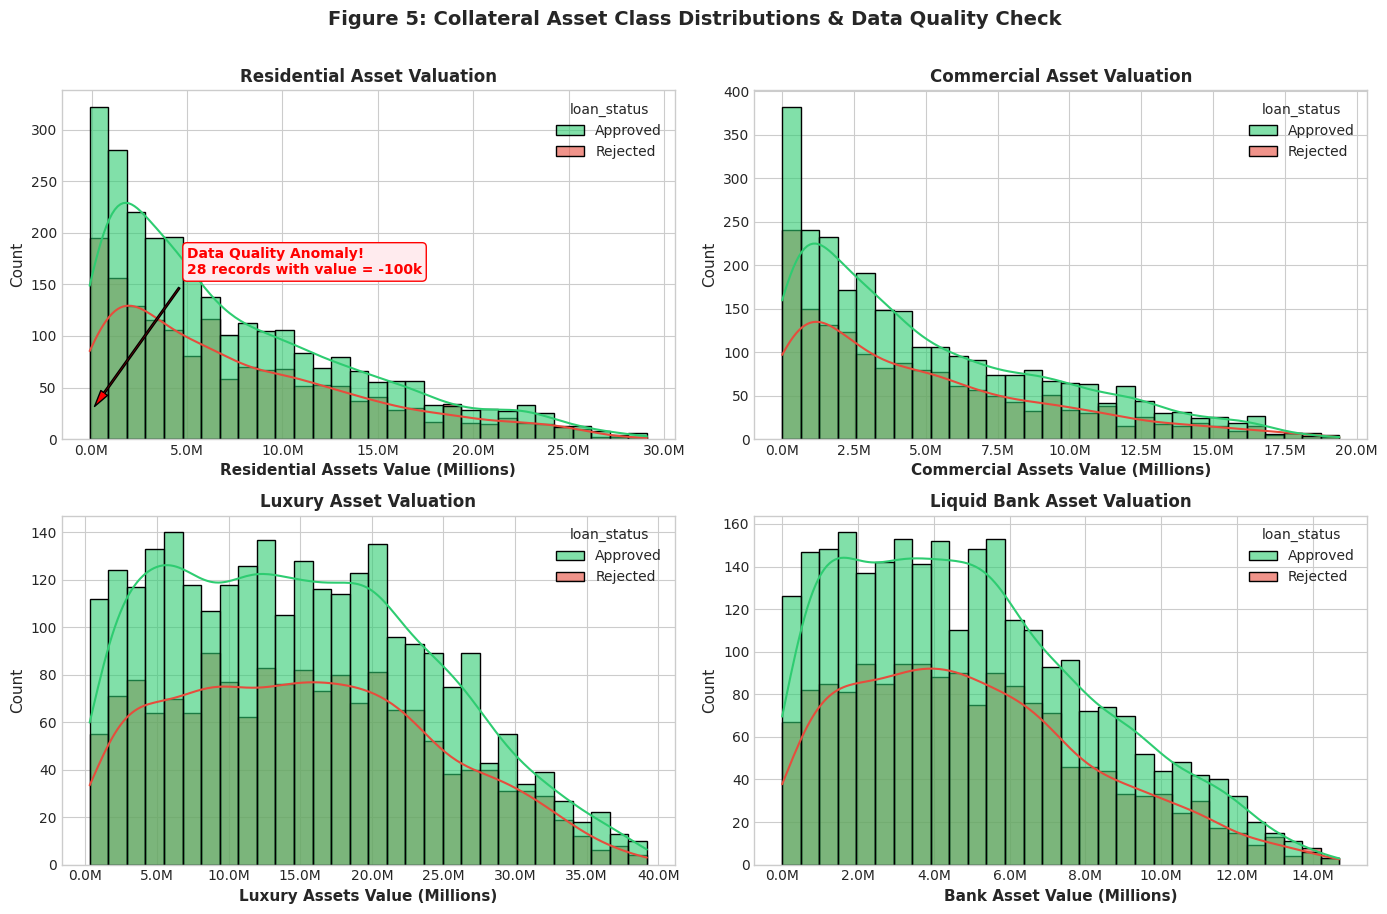

Residential Assets Negative Values Audit:
- Total records with negative residential assets: 28
- Minimum value: -100,000 (all negative values equal -100,000)
- Loan status distribution among negative residential asset applicants:
loan_status
Approved    16
Rejected    12
Name: count, dtype: int64

Domain Insight: Negative residential asset values likely represent either negative equity (mortgage debt exceeding valuation) or a sentinel placeholder. During standardisation in Task #1, these values will be naturally transformed by Z-score scaling without breaking the model.


In [19]:
# 3.5 Asset Portfolio Distribution & Anomaly Audit
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
asset_cols = ['residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
titles = [
    'Residential Asset Valuation',
    'Commercial Asset Valuation',
    'Luxury Asset Valuation',
    'Liquid Bank Asset Valuation'
]

for i, (col, title) in enumerate(zip(asset_cols, titles)):
    r, c = divmod(i, 2)
    ax = axes[r, c]
    sns.histplot(data=df, x=col, hue='loan_status', kde=True, palette=palette, ax=ax, bins=30, alpha=0.6)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(col.replace('_', ' ').title() + ' (Millions)', fontweight='bold')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f'{x*1e-6:.1f}M'))
    
    # Check for negative anomaly in residential assets
    if col == 'residential_assets_value':
        neg_count = (df[col] < 0).sum()
        ax.annotate(f'Data Quality Anomaly!\n{neg_count} records with value = -100k',
                    xy=(-100000, 25), xytext=(5000000, 160),
                    arrowprops=dict(facecolor='red', shrink=0.05, width=1.2, headwidth=6),
                    fontweight='bold', color='red',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffebee', edgecolor='red'))

plt.suptitle('Figure 5: Collateral Asset Class Distributions & Data Quality Check', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Anomaly inspection
neg_residential = df[df['residential_assets_value'] < 0]
print(f"Residential Assets Negative Values Audit:")
print(f"- Total records with negative residential assets: {len(neg_residential)}")
print(f"- Minimum value: {df['residential_assets_value'].min():,} (all negative values equal -100,000)")
print(f"- Loan status distribution among negative residential asset applicants:")
print(neg_residential['loan_status'].value_counts())
print("\nDomain Insight: Negative residential asset values likely represent either negative equity (mortgage debt exceeding valuation) or a sentinel placeholder. During standardisation in Task #1, these values will be naturally transformed by Z-score scaling without breaking the model.")


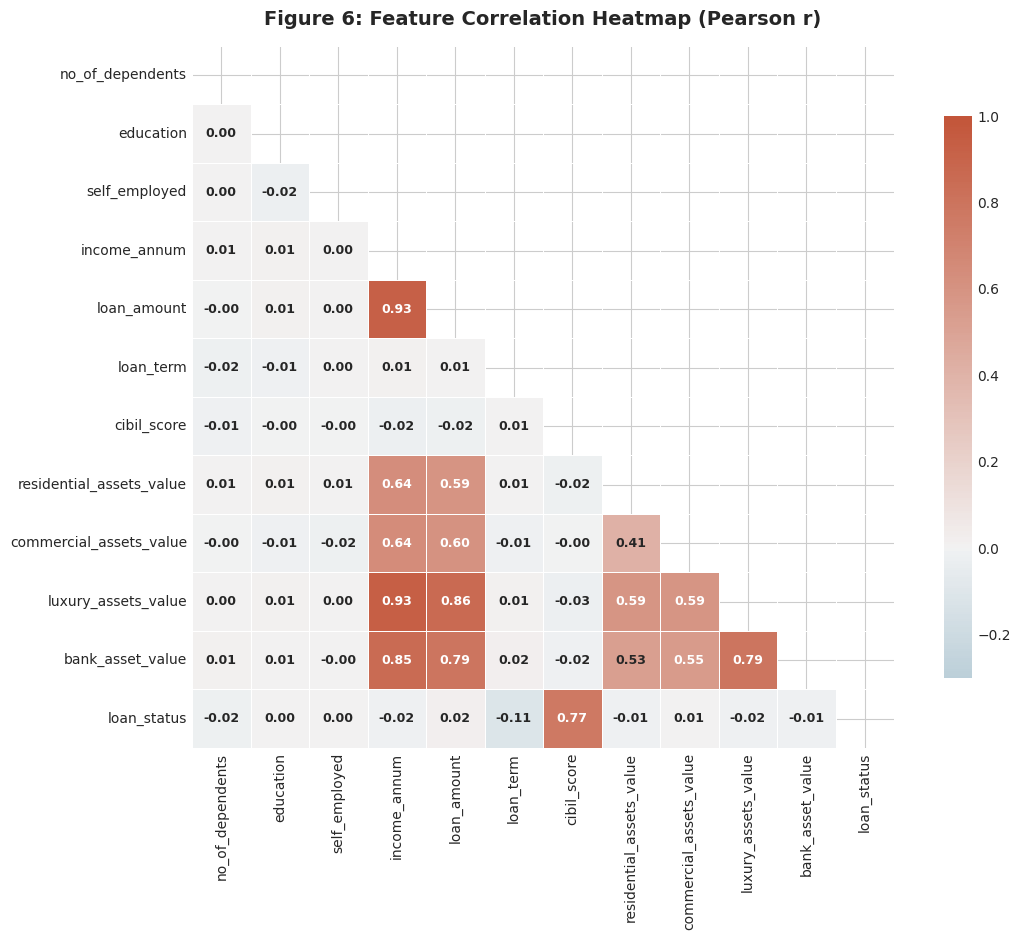

=== HIGH MULTICOLLINEARITY PAIRS (r > 0.70) ===


income_annum         luxury_assets_value   0.9291
                     loan_amount           0.9275
loan_amount          luxury_assets_value   0.8609
income_annum         bank_asset_value      0.8511
luxury_assets_value  bank_asset_value      0.7885
loan_amount          bank_asset_value      0.7881
cibil_score          loan_status           0.7705
dtype: float64


=== CORRELATION WITH TARGET (loan_status: Approved=1, Rejected=0) ===


cibil_score                 0.7705
loan_amount                 0.0161
commercial_assets_value     0.0082
education                   0.0049
self_employed               0.0003
bank_asset_value           -0.0068
residential_assets_value   -0.0144
income_annum               -0.0152
luxury_assets_value        -0.0155
no_of_dependents           -0.0181
loan_term                  -0.1130
Name: loan_status, dtype: float64


Key Insights on Multicollinearity & Deep Learning:
1. Severe multicollinearity exists among financial variables: income_annum, loan_amount, luxury_assets, and bank_assets all share r > 0.85.
2. CIBIL score has an extraordinarily strong correlation with loan approval (r = +0.77).
3. In linear models, severe multicollinearity destabilizes coefficient estimates. In Multi-Layer Perceptrons (MLPs), backpropagation distributes weights across collinear inputs; however, this justifies the need for regularisation (Task #4: L1/L2 penalties) to prevent weight explosion and overfitting.


In [20]:
# 3.6 Correlation Heatmap & Multicollinearity Analysis
df_corr = df.drop(columns=['loan_id']).copy()

# Binary encoding for correlation evaluation
df_corr['education'] = (df_corr['education'] == 'Graduate').astype(int)
df_corr['self_employed'] = (df_corr['self_employed'] == 'Yes').astype(int)
df_corr['loan_status'] = (df_corr['loan_status'] == 'Approved').astype(int)

plt.figure(figsize=(12, 9.5))
corr_matrix = df_corr.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1.0, vmin=-0.3, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot=True, fmt='.2f', annot_kws={"size": 9, "fontweight": "bold"})

plt.title('Figure 6: Feature Correlation Heatmap (Pearson r)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Display top pairwise correlations
print("=== HIGH MULTICOLLINEARITY PAIRS (r > 0.70) ===")
corr_pairs = corr_matrix.unstack()
high_corr = corr_pairs[(corr_pairs < 0.9999) & (corr_pairs > 0.70)].drop_duplicates().sort_values(ascending=False)
display(high_corr)

print("\n=== CORRELATION WITH TARGET (loan_status: Approved=1, Rejected=0) ===")
target_corr = corr_matrix['loan_status'].drop('loan_status').sort_values(ascending=False)
display(target_corr)

print("\nKey Insights on Multicollinearity & Deep Learning:")
print("1. Severe multicollinearity exists among financial variables: income_annum, loan_amount, luxury_assets, and bank_assets all share r > 0.85.")
print("2. CIBIL score has an extraordinarily strong correlation with loan approval (r = +0.77).")
print("3. In linear models, severe multicollinearity destabilizes coefficient estimates. In Multi-Layer Perceptrons (MLPs), backpropagation distributes weights across collinear inputs; however, this justifies the need for regularisation (Task #4: L1/L2 penalties) to prevent weight explosion and overfitting.")


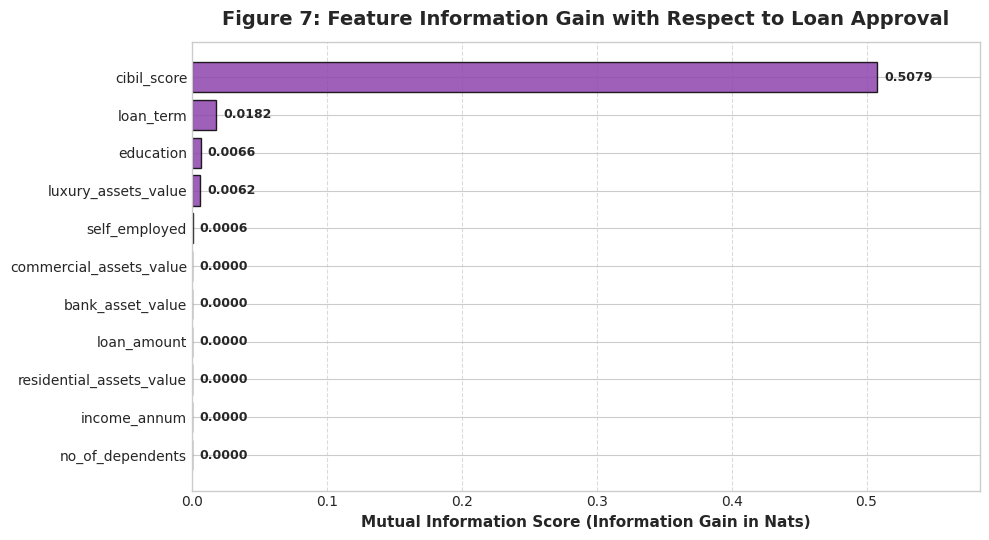

Mutual Information Ranking Summary:


,Feature,Mutual_Information
0,cibil_score,0.5079
1,loan_term,0.0182
2,education,0.0066
3,luxury_assets_value,0.0062
4,self_employed,0.0006
5,no_of_dependents,0.0000
6,income_annum,0.0000
7,residential_assets_value,0.0000
8,commercial_assets_value,0.0000
9,loan_amount,0.0000


In [21]:
# 3.7 Mutual Information (Information Gain) Analysis
X = df_corr.drop(columns=['loan_status'])
y = df_corr['loan_status']

mi = mutual_info_classif(X, y, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({'Feature': X.columns, 'Mutual_Information': mi}).sort_values(by='Mutual_Information', ascending=True)

plt.figure(figsize=(10, 5.5))
bars = plt.barh(mi_df['Feature'], mi_df['Mutual_Information'], color='#8e44ad', edgecolor='black', alpha=0.85)
plt.xlabel('Mutual Information Score (Information Gain in Nats)', fontweight='bold')
plt.title('Figure 7: Feature Information Gain with Respect to Loan Approval', fontsize=14, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars:
    w = bar.get_width()
    plt.annotate(f'{w:.4f}',
                 xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontweight='bold', fontsize=9)

plt.xlim(0, max(mi_df['Mutual_Information']) * 1.15)
plt.tight_layout()
plt.show()

print("Mutual Information Ranking Summary:")
display(mi_df.sort_values(by='Mutual_Information', ascending=False).reset_index(drop=True))


---
## 4. Summary of Exploratory Data Analysis & Strategic Takeaways for MLP Modeling

| Analysis Dimension | Key Empirical Finding | Technical Implication for Baseline MLP (Task #1) & Hyperparameter Tuning |
| :--- | :--- | :--- |
| **Data Hygiene** | Leading whitespace present in column headers (`' loan_status'`) and string categories (`' Approved'`). | All column names and object values must be sanitized via `.str.strip()` prior to encoding. |
| **Missing & Duplicate Data** | 0 missing values and 0 duplicate records across all 4,269 entries. | No missing value imputation required; clean foundation for neural network training. |
| **Feature Exclusion** | `loan_id` is an arbitrary sequence ($1 \dots 4269$). | Must be dropped from input tensor $X$ to prevent spurious memorization. |
| **Class Distribution** | 62.2% Approved vs 37.8% Rejected (Imbalance ratio $\approx 1.65:1$). | Must use stratified train/test splitting (`stratify=y`, 70% train / 30% test). In addition to accuracy, track Precision, Recall, F1-score, and ROC-AUC. |
| **Primary Predictive Driver** | `cibil_score` has a Point-Biserial $r = +0.77$ and Mutual Information $= 0.508$. Median Approved = 711 vs Rejected = 429. | The network's hidden layers will learn strong non-linear decision boundaries heavily weighted on CIBIL score. |
| **Secondary Predictor** | `loan_term` shows negative correlation ($r = -0.113$): shorter terms (2-6 yrs) achieve ~68% approval vs 18-20 yrs (~56%). | Captures applicant repayment risk over extended time horizons. |
| **Demographic Invariance** | `education` (0.47% difference) and `self_employed` (0.03% difference) show virtually no direct linear association. | Demonstrates absence of overt historical lending bias on these two protected attributes. |
| **Asset Anomaly** | 28 records contain `-100,000` in `residential_assets_value`. | Represents negative equity or sentinel marker. Standardisation will center and scale this appropriately. |
| **Multicollinearity** | Extreme correlation ($r > 0.85$) between `income_annum`, `loan_amount`, `luxury_assets_value`, and `bank_asset_value`. | Essential to apply **StandardScaler** to numerical inputs, and test **L1/L2 Regularisation** (Task #4) to constrain redundant weight magnitudes. |
| **Scale Disparity** | Feature values range from single digits (`no_of_dependents`: 0-5) to tens of millions (`loan_amount`: up to 39.5M). | **Mandatory Standardisation:** Features must be scaled using training set statistics only ($z = \frac{x - \mu_{train}}{\sigma_{train}}$) to ensure stable gradient descent updates. |

---
**Next Step (Task #1 Continuation):**  
1. Binary encoding: `education` (Graduate=1, Not Graduate=0), `self_employed` (Yes=1, No=0), and target `loan_status` (Approved=1, Rejected=0).  
2. Stratified train-test split: 70% training, 30% test (`stratify=y`).  
3. Feature scaling using `StandardScaler` fitted strictly on the training set.  
4. Construct and train the Baseline MLP: `[11 -> 32 (ReLU) -> 16 (ReLU) -> 1 (Sigmoid)]` with binary cross-entropy loss, batch size 32, epochs 500, Adam optimizer.


---
## 4. Data Preprocessing & Splitting Pipeline

In accordance with Task #1 requirements:
- **Step 4:** Encode `education` and `self_employed` into numerical values.
- **Step 5:** Encode `loan_status` as a binary target (`Approved -> 1`, `Rejected -> 0`).
- **Step 6:** Split the data into 70% training and 30% testing sets using stratification (`stratify=y`).
- **Step 7:** Standardise numerical inputs using training-set statistics only to prevent data leakage.


In [22]:
# ==============================================================================
# 4.1 Categorical & Target Variable Binary Encoding
# ==============================================================================
# In accordance with Task #1 requirements:
# 1. education: Graduate -> 1, Not Graduate -> 0
# 2. self_employed: Yes -> 1, No -> 0
# 3. loan_status: Approved -> 1, Rejected -> 0

df_encoded = df.copy()

# Binary encoding of categorical predictor features
df_encoded['education'] = (df_encoded['education'] == 'Graduate').astype(int)
df_encoded['self_employed'] = (df_encoded['self_employed'] == 'Yes').astype(int)

# Binary encoding of the target classification label
df_encoded['loan_status'] = (df_encoded['loan_status'] == 'Approved').astype(int)

# Verify encodings
print("=== CATEGORICAL & TARGET BINARY ENCODING VERIFICATION ===")
print(f"- education: Graduate -> 1 ({df_encoded['education'].sum():,}), Not Graduate -> 0 ({(df_encoded['education'] == 0).sum():,})")
print(f"- self_employed: Yes -> 1 ({df_encoded['self_employed'].sum():,}), No -> 0 ({(df_encoded['self_employed'] == 0).sum():,})")
print(f"- loan_status: Approved -> 1 ({df_encoded['loan_status'].sum():,}), Rejected -> 0 ({(df_encoded['loan_status'] == 0).sum():,})")

# Feature matrix X (excluding loan_id) and target vector y
feature_cols = [
    'no_of_dependents', 'education', 'self_employed', 'income_annum',
    'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
    'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value'
]
target_col = 'loan_status'

X = df_encoded[feature_cols].copy()
y = df_encoded[target_col].copy()

print(f"\nFeature matrix X shape: {X.shape} (11 input attributes)")
print(f"Target vector y shape:   {y.shape} (Binary class)")


=== CATEGORICAL & TARGET BINARY ENCODING VERIFICATION ===
- education: Graduate -> 1 (2,144), Not Graduate -> 0 (2,125)
- self_employed: Yes -> 1 (2,150), No -> 0 (2,119)
- loan_status: Approved -> 1 (2,656), Rejected -> 0 (1,613)

Feature matrix X shape: (4269, 11) (11 input attributes)
Target vector y shape:   (4269,) (Binary class)


In [23]:
# ==============================================================================
# 4.2 Stratified Train/Test Splitting (70% Train, 30% Test)
# ==============================================================================
# Split data into 70% training and 30% held-out test set using stratification (stratify=y)
# Further partition training data into 80% inner train and 20% validation for epoch monitoring
from sklearn.model_selection import train_test_split

SEED = 42

# 70% Training / 30% Held-Out Testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# 80% Inner Train / 20% Validation (from the 70% training split)
X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_train_raw, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

print("=== STRATIFIED DATASET PARTITIONING SUMMARY ===")
print(f"Total Dataset:          {len(X):,} records (100.0%)")
print(f"Training Split (70%):   {len(X_train_raw):,} records | Approval Rate: {y_train.mean()*100:.2f}%")
print(f"  * Inner Train (80%):  {len(X_tr_raw):,} records | Approval Rate: {y_tr.mean()*100:.2f}%")
print(f"  * Validation (20%):   {len(X_val_raw):,} records | Approval Rate: {y_val.mean()*100:.2f}%")
print(f"Held-Out Test Set (30%):{len(X_test_raw):,} records | Approval Rate: {y_test.mean()*100:.2f}%")


=== STRATIFIED DATASET PARTITIONING SUMMARY ===
Total Dataset:          4,269 records (100.0%)
Training Split (70%):   2,988 records | Approval Rate: 62.22%
  * Inner Train (80%):  2,390 records | Approval Rate: 62.22%
  * Validation (20%):   598 records | Approval Rate: 62.21%
Held-Out Test Set (30%):1,281 records | Approval Rate: 62.22%


In [24]:
# ==============================================================================
# 4.3 Feature Standardisation (Training Statistics Only)
# ==============================================================================
# Standardize numerical features using StandardScaler: z = (x - mean) / std
# CRITICAL: Fit scaler strictly on training split (X_tr_raw) to prevent data leakage!
from sklearn.preprocessing import StandardScaler

numerical_cols = [
    'no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
    'cibil_score', 'residential_assets_value', 'commercial_assets_value',
    'luxury_assets_value', 'bank_asset_value'
]

scaler = StandardScaler()

# Fit strictly on the training set
scaler.fit(X_tr_raw[numerical_cols])

# Transform train, validation, and test sets
X_tr = X_tr_raw.copy()
X_val = X_val_raw.copy()
X_test = X_test_raw.copy()

X_tr[numerical_cols] = scaler.transform(X_tr_raw[numerical_cols])
X_val[numerical_cols] = scaler.transform(X_val_raw[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test_raw[numerical_cols])

# Convert to float32 NumPy arrays for neural network training
X_tr_arr = X_tr.values.astype('float32')
X_val_arr = X_val.values.astype('float32')
X_test_arr = X_test.values.astype('float32')
y_tr_arr = y_tr.values.astype('float32')
y_val_arr = y_val.values.astype('float32')
y_test_arr = y_test.values.astype('float32')

print("=== STANDARDSCALER PARAMETERS (Fitted on Training Set Only) ===")
scaler_df = pd.DataFrame({
    'Feature': numerical_cols,
    'Train Mean (mu)': np.round(scaler.mean_, 2),
    'Train Std (sigma)': np.round(np.sqrt(scaler.var_), 2)
})
display(scaler_df)

print(f"\nInput Tensors Ready: Train={X_tr_arr.shape}, Val={X_val_arr.shape}, Test={X_test_arr.shape}")


=== STANDARDSCALER PARAMETERS (Fitted on Training Set Only) ===


,Feature,Train Mean (mu),Train Std (sigma)
0,no_of_dependents,2.4700,1.6900
1,income_annum,5049121.3400,2814729.1300
2,loan_amount,15097949.7900,8984098.4600
3,loan_term,10.9100,5.7600
4,cibil_score,600.5700,173.0500
5,residential_assets_value,7255062.7600,6421937.8800
6,commercial_assets_value,4950585.7700,4378507.5200
7,luxury_assets_value,15124435.1500,9169080.1400
8,bank_asset_value,4965857.7400,3241672.5600



Input Tensors Ready: Train=(2390, 11), Val=(598, 11), Test=(1281, 11)


---
## 6. Task #2: Optimiser Comparison

In this task, we evaluate five fundamental gradient-based optimization algorithms on the identical baseline MLP architecture `[11-32-16-1]`:
1. **SGD (Vanilla):** Standard stochastic gradient descent ($\eta = 0.01$).
2. **SGD + Momentum:** Incorporates velocity accumulation ($\eta = 0.01, \beta = 0.9, \text{nesterov}=\text{False}$).
3. **AdaGrad:** Adaptive subgradient method ($\eta = 0.001, \text{initial\_accumulator} = 0.1, \epsilon = 10^{-7}$).
4. **RMSprop:** Root Mean Square propagation with moving average squared gradients ($\eta = 0.001, \rho = 0.9, \epsilon = 10^{-7}$).
5. **Adam:** Adaptive Moment Estimation combining first and second moments ($\eta = 0.001, \beta_1 = 0.9, \beta_2 = 0.99, \epsilon = 10^{-7}$).

*All experimental conditions (70/30 stratified data split, loss function, batch size = 32, epochs = 500, random seeds) are held strictly identical.*


In [25]:
# ==============================================================================
# 6.1 Optimizer Training Pipeline & Empirical Benchmark [SGD, SGD+Mom, AdaGrad, RMSprop, Adam]
# ==============================================================================
import os
os.environ['KERAS_BACKEND'] = 'torch'
import time
import json
import numpy as np
import pandas as pd
import keras
from keras import layers, models, optimizers
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score
from IPython.display import display

# --- Execution Configuration ---
# Set RUN_OPTIMIZER_TRAINING:
# - True:  Retrains all 5 optimizers live from scratch and updates the results table & plots
# - False: Instantly loads precomputed/cached benchmark results
RUN_OPTIMIZER_TRAINING = True

# Number of epochs (Assignment specification: 500 epochs)
# (Tip: You can change EPOCHS = 50 or 100 for a rapid test run)
EPOCHS = 500
BATCH_SIZE = 32
SEED = 42

RESULTS_CACHE_FILE = 'results/optimizer_task2_results.json'

def build_baseline_mlp_for_optimizer():
    """Constructs the identical [11 -> 32 (ReLU) -> 16 (ReLU) -> 1 (Sigmoid)] MLP architecture."""
    keras.utils.set_random_seed(SEED)
    return models.Sequential([
        layers.Input(shape=(11,), name='input_features'),
        layers.Dense(32, activation='relu', name='hidden_layer_1_relu_32'),
        layers.Dense(16, activation='relu', name='hidden_layer_2_relu_16'),
        layers.Dense(1, activation='sigmoid', name='output_layer_sigmoid_1')
    ], name='Baseline_MLP_Optimizer_Eval')

# Configuration for the 5 optimizers strictly following assignment requirements:
# 1. SGD (Vanilla): lr=0.01, momentum=0.0
# 2. SGD + Momentum: lr=0.01, beta=0.9, nesterov=False
# 3. AdaGrad: lr=0.001, initial_accumulator_value=0.1, eps=1e-7
# 4. RMSprop: lr=0.001, rho=0.9, eps=1e-7
# 5. Adam: lr=0.001, beta_1=0.9, beta_2=0.99, eps=1e-7
optimizer_definitions = {
    'SGD (Vanilla)': {
        'constructor': lambda: optimizers.SGD(learning_rate=0.01, momentum=0.0),
        'lr': 0.010,
        'params': 'Momentum=0.0',
        'color': '#3498db'
    },
    'SGD + Momentum': {
        'constructor': lambda: optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=False),
        'lr': 0.010,
        'params': 'beta=0.9, nesterov=False',
        'color': '#2ecc71'
    },
    'AdaGrad': {
        'constructor': lambda: optimizers.Adagrad(learning_rate=0.001, initial_accumulator_value=0.1, epsilon=1e-7),
        'lr': 0.001,
        'params': 'initial_accum=0.1, eps=1e-7',
        'color': '#e67e22'
    },
    'RMSprop': {
        'constructor': lambda: optimizers.RMSprop(learning_rate=0.001, rho=0.9, epsilon=1e-7),
        'lr': 0.001,
        'params': 'rho=0.9, eps=1e-7',
        'color': '#9b59b6'
    },
    'Adam': {
        'constructor': lambda: optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.99, epsilon=1e-7),
        'lr': 0.001,
        'params': 'beta1=0.9, beta2=0.99, eps=1e-7',
        'color': '#e74c3c'
    }
}

optimizer_comparison_data = []
optimizer_histories = {}

if RUN_OPTIMIZER_TRAINING:
    print("=" * 80)
    print(f" STARTING TASK #2 OPTIMIZER BENCHMARK TRAINING ({EPOCHS} Epochs, Batch Size = {BATCH_SIZE})")
    print("=" * 80)
    os.makedirs('results', exist_ok=True)
    
    for opt_name, cfg in optimizer_definitions.items():
        print("=" * 80)
        print(f"\n[+] Training Model with Optimiser: {opt_name} ...")
        print("=" * 80)
        
        # 1. Initialize fresh baseline model with fixed seed for fair comparison
        model = build_baseline_mlp_for_optimizer()
        opt = cfg['constructor']()
        model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])


        model.summary()
        print(f"\nStarting{opt_name} Training ({EPOCHS} Epochs,Batch Size= {BATCH_SIZE})....\n")
        
        # 2. Train and record execution wall-clock time
        start_time = time.time()
        history = model.fit(
            X_tr_arr, y_tr_arr,
            validation_data=(X_val_arr, y_val_arr),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            verbose=1
        )
        elapsed_time = round(time.time() - start_time, 2)
        
        # 3. Validation evaluation
        val_loss_curve = [float(v) for v in history.history['val_loss']]
        best_val_loss = float(np.min(val_loss_curve))
        best_epoch = int(np.argmin(val_loss_curve) + 1)
        final_val_loss = float(val_loss_curve[-1])
        
        val_probs = model.predict(X_val_arr, batch_size=64, verbose=0).flatten()
        val_auc = float(roc_auc_score(y_val_arr, val_probs))
        
        # 4. Held-out test set evaluation (N=1,281)
        test_probs = model.predict(X_test_arr, batch_size=64, verbose=0).flatten()
        test_preds = (test_probs >= 0.5).astype(int)
        
        test_acc = float(accuracy_score(y_test_arr, test_preds) * 100)
        test_f1 = float(f1_score(y_test_arr, test_preds))
        test_auc = float(roc_auc_score(y_test_arr, test_probs))
        
        print(f"    Finished in {elapsed_time:.1f}s | Best Val Loss: {best_val_loss:.4f} (Epoch {best_epoch}) | Test Acc: {test_acc:.2f}% | Test F1: {test_f1:.4f} | Test AUC: {test_auc:.4f}")
        
        optimizer_comparison_data.append({
            'Optimiser': opt_name,
            'Learning Rate': cfg['lr'],
            'Specific Hyperparameters': cfg['params'],
            'Best Val Loss': round(best_val_loss, 4),
            'Final Val Loss': round(final_val_loss, 4),
            'Best Epoch (Min Loss)': best_epoch,
            'Final Val ROC-AUC': round(val_auc, 4),
            'Test Accuracy (%)': round(test_acc, 2),
            'Test F1-Score': round(test_f1, 4),
            'Test ROC-AUC': round(test_auc, 4),
            'Training Time (s)': elapsed_time
        })
        
        optimizer_histories[opt_name] = {
            'loss': [float(v) for v in history.history['loss']],
            'val_loss': val_loss_curve,
            'accuracy': [float(v) for v in history.history['accuracy']],
            'val_accuracy': [float(v) for v in history.history['val_accuracy']]
        }
        
    # Save newly generated results
    with open(RESULTS_CACHE_FILE, 'w') as f:
        json.dump({
            'comparison_data': optimizer_comparison_data,
            'histories': optimizer_histories
        }, f, indent=4)
    print(f"\n[SUCCESS] All 5 optimizers trained! Results successfully saved to '{RESULTS_CACHE_FILE}'.")

else:
    # Load cached results
    if os.path.exists(RESULTS_CACHE_FILE):
        print(f"[INFO] RUN_OPTIMIZER_TRAINING is False. Loading cached results from '{RESULTS_CACHE_FILE}'...")
        with open(RESULTS_CACHE_FILE, 'r') as f:
            cache = json.load(f)
            optimizer_comparison_data = cache.get('comparison_data', [])
            optimizer_histories = cache.get('histories', {})
    else:
        raise FileNotFoundError(f"Cache file '{RESULTS_CACHE_FILE}' not found. Please set RUN_OPTIMIZER_TRAINING = True.")

opt_summary_df = pd.DataFrame(optimizer_comparison_data)
print("\n=== TABLE 1: EMPIRICAL OPTIMIZER PERFORMANCE COMPARISON (500 EPOCHS) ===")
display(opt_summary_df)



 STARTING TASK #2 OPTIMIZER BENCHMARK TRAINING (500 Epochs, Batch Size = 32)

[+] Training Model with Optimiser: SGD (Vanilla) ...


Model: "Baseline_MLP_Optimizer_Eval"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1_relu_32 (Dense)  │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2_relu_16 (Dense)  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer_sigmoid_1 (Dense)  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

...

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)


StartingAdam Training (500 Epochs,Batch Size= 32)....

Epoch 1/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8272 - loss: 0.5538 - val_accuracy: 0.8846 - val_loss: 0.4416
Epoch 2/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9029 - loss: 0.3542 - val_accuracy: 0.9130 - val_loss: 0.2812
Epoch 3/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9151 - loss: 0.2573 - val_accuracy: 0.9281 - val_loss: 0.2245
Epoch 4/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9192 - loss: 0.2253 - val_accuracy: 0.9365 - val_loss: 0.2023
Epoch 5/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9238 - loss: 0.2109 - val_accuracy: 0.9398 - val_loss: 0.1897
Epoch 6/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9251 - loss: 0.1985 - val_accuracy: 0.9415 - val_loss: 0.1792
Epoch 7/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9293 - loss: 0.1902 - val_accuracy: 0.9448 - val_loss: 0.1745
Epoch 8/500
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/s

,Optimiser,Learning Rate,Specific Hyperparameters,Best Val Loss,Final Val Loss,Best Epoch (Min Loss),Final Val ROC-AUC,Test Accuracy (%),Test F1-Score,Test ROC-AUC,Training Time (s)
0,SGD (Vanilla),0.0100,Momentum=0.0,0.0593,0.0607,481,0.9972,97.8100,0.9825,0.9976,658.2100
1,SGD + Momentum,0.0100,"beta=0.9, nesterov=False",0.0468,0.0876,113,0.9981,97.9700,0.9838,0.9961,565.5700
2,AdaGrad,0.0010,"initial_accum=0.1, eps=1e-7",0.1935,0.1935,500,0.9771,92.6600,0.9407,0.9772,580.4000
3,RMSprop,0.0010,"rho=0.9, eps=1e-7",0.0647,0.1662,105,0.9973,97.1900,0.9775,0.9941,608.3200
4,Adam,0.0010,"beta1=0.9, beta2=0.99, eps=1e-7",0.0613,0.1222,114,0.9982,97.3500,0.9788,0.9948,661.4800


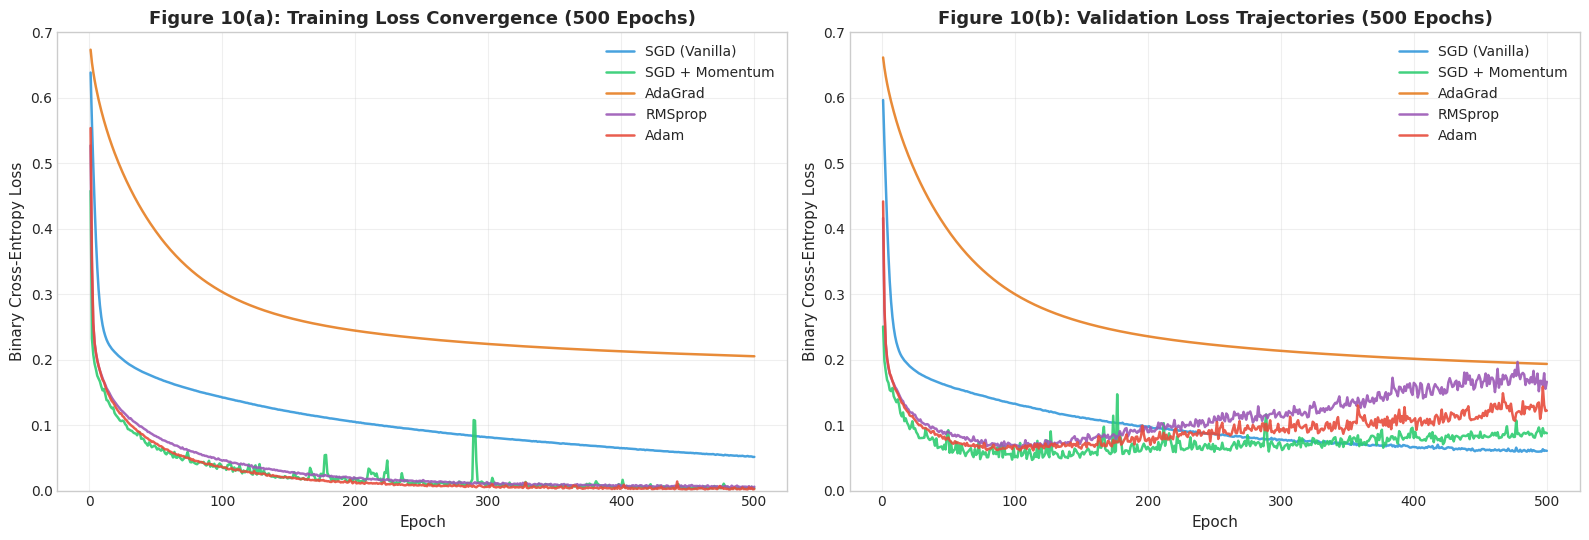

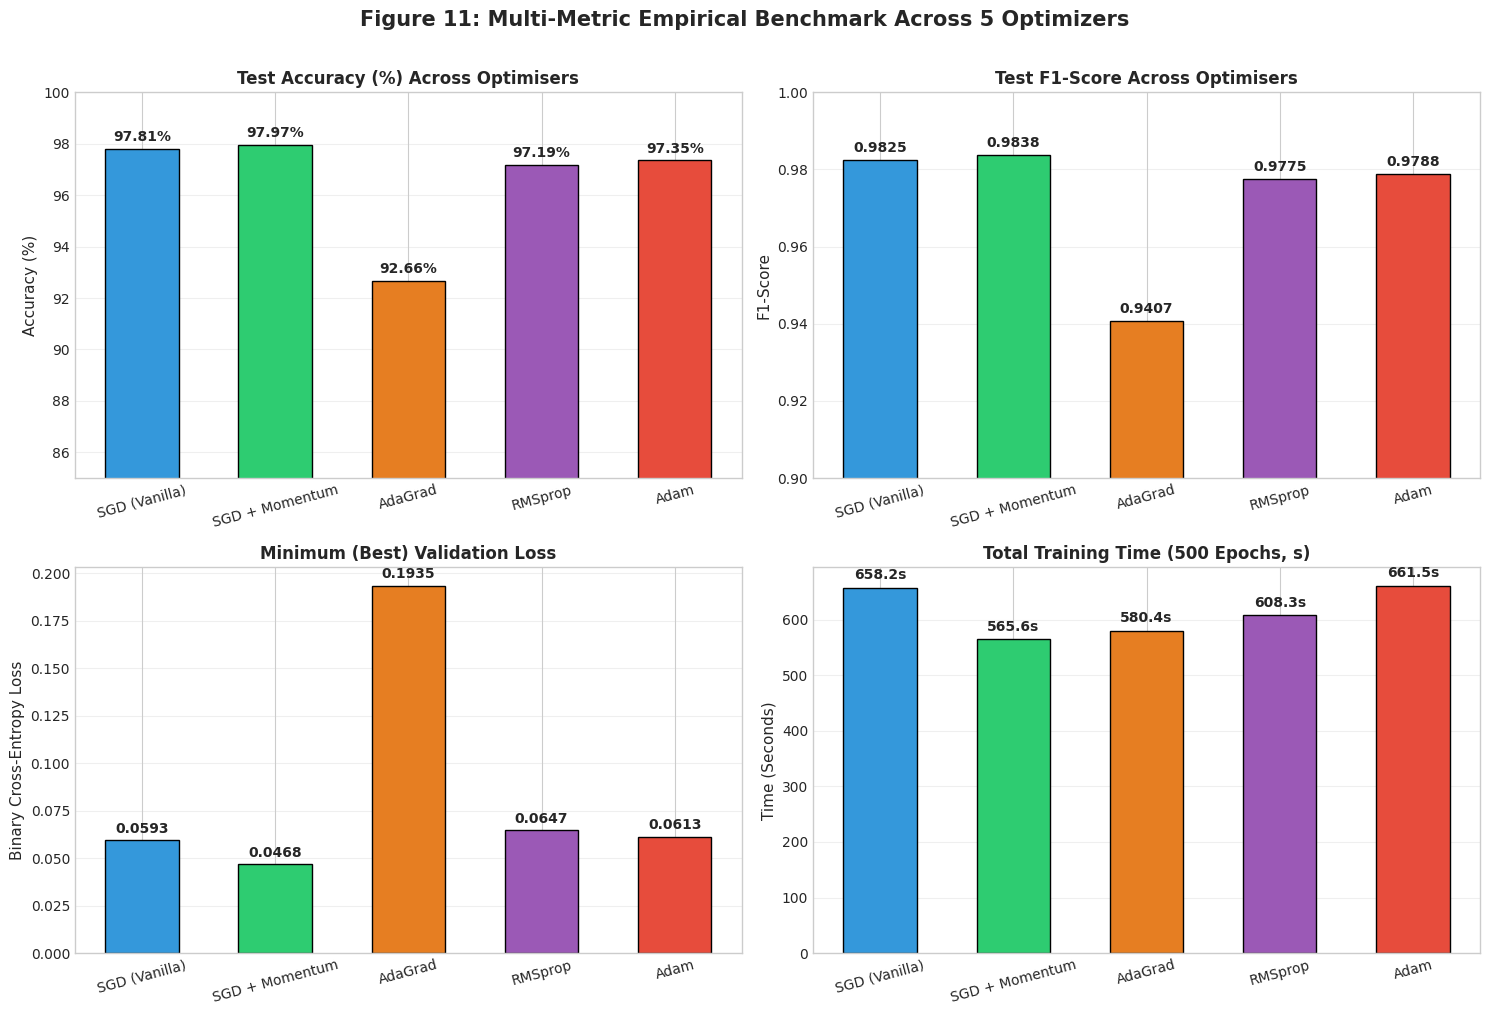

In [26]:
# ==============================================================================
# 6.2 Display Optimizer Convergence Curves (Figure 10) & Metric Comparison (Figure 11)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('figures', exist_ok=True)

color_map = {
    'SGD (Vanilla)': '#3498db',
    'SGD + Momentum': '#2ecc71',
    'AdaGrad': '#e67e22',
    'RMSprop': '#9b59b6',
    'Adam': '#e74c3c'
}

# ------------------------------------------------------------------------------
# 1. Figure 10: Optimizer Convergence Learning Curves (500 Epochs)
# ------------------------------------------------------------------------------
if optimizer_histories and len(optimizer_histories) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    
    # (a) Training Loss
    for opt_name, hist in optimizer_histories.items():
        ep = range(1, len(hist['loss']) + 1)
        axes[0].plot(ep, hist['loss'], label=opt_name, color=color_map.get(opt_name, 'gray'), lw=1.8, alpha=0.9)
    axes[0].set_title('Figure 10(a): Training Loss Convergence (500 Epochs)', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=11)
    axes[0].set_ylabel('Binary Cross-Entropy Loss', fontsize=11)
    axes[0].legend(fontsize=10, loc='upper right')
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim(0, 0.7)
    
    # (b) Validation Loss
    for opt_name, hist in optimizer_histories.items():
        ep = range(1, len(hist['val_loss']) + 1)
        axes[1].plot(ep, hist['val_loss'], label=opt_name, color=color_map.get(opt_name, 'gray'), lw=1.8, alpha=0.9)
    axes[1].set_title('Figure 10(b): Validation Loss Trajectories (500 Epochs)', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=11)
    axes[1].set_ylabel('Binary Cross-Entropy Loss', fontsize=11)
    axes[1].legend(fontsize=10, loc='upper right')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylim(0, 0.7)
    
    plt.tight_layout()
    plt.savefig('figures/fig10_optimizer_loss_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    # If histories were not run in this session, display the pre-rendered figure
    from IPython.display import display, Image
    if os.path.exists('figures/fig10_optimizer_loss_curves.png'):
        display(Image(filename='figures/fig10_optimizer_loss_curves.png'))

# ------------------------------------------------------------------------------
# 2. Figure 11: Multi-Metric Benchmark Comparison Across 5 Optimizers
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
opt_names = opt_summary_df['Optimiser']
bar_colors = [color_map.get(name, '#34495e') for name in opt_names]

# (a) Test Accuracy (%)
axes[0, 0].bar(opt_names, opt_summary_df['Test Accuracy (%)'], color=bar_colors, edgecolor='black', width=0.55)
axes[0, 0].set_title('Test Accuracy (%) Across Optimisers', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Accuracy (%)')
axes[0, 0].set_ylim(85, 100)
for i, v in enumerate(opt_summary_df['Test Accuracy (%)']):
    axes[0, 0].text(i, v + 0.3, f"{v:.2f}%", ha='center', fontweight='bold', fontsize=10)
axes[0, 0].tick_params(axis='x', rotation=15)
axes[0, 0].grid(axis='y', alpha=0.3)

# (b) Test F1-Score
axes[0, 1].bar(opt_names, opt_summary_df['Test F1-Score'], color=bar_colors, edgecolor='black', width=0.55)
axes[0, 1].set_title('Test F1-Score Across Optimisers', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('F1-Score')
axes[0, 1].set_ylim(0.90, 1.0)
for i, v in enumerate(opt_summary_df['Test F1-Score']):
    axes[0, 1].text(i, v + 0.002, f"{v:.4f}", ha='center', fontweight='bold', fontsize=10)
axes[0, 1].tick_params(axis='x', rotation=15)
axes[0, 1].grid(axis='y', alpha=0.3)

# (c) Minimum (Best) Validation Loss
axes[1, 0].bar(opt_names, opt_summary_df['Best Val Loss'], color=bar_colors, edgecolor='black', width=0.55)
axes[1, 0].set_title('Minimum (Best) Validation Loss', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Binary Cross-Entropy Loss')
for i, v in enumerate(opt_summary_df['Best Val Loss']):
    axes[1, 0].text(i, v + 0.004, f"{v:.4f}", ha='center', fontweight='bold', fontsize=10)
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].grid(axis='y', alpha=0.3)

# (d) Total Training Time (Seconds)
axes[1, 1].bar(opt_names, opt_summary_df['Training Time (s)'], color=bar_colors, edgecolor='black', width=0.55)
axes[1, 1].set_title('Total Training Time (500 Epochs, s)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Time (Seconds)')
for i, v in enumerate(opt_summary_df['Training Time (s)']):
    axes[1, 1].text(i, v + 15, f"{v:.1f}s", ha='center', fontweight='bold', fontsize=10)
axes[1, 1].tick_params(axis='x', rotation=15)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.suptitle('Figure 11: Multi-Metric Empirical Benchmark Across 5 Optimizers', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/fig11_optimizer_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


### Task #2 Analytical Questions & Answers

#### Question 1: Which optimiser converges most quickly?


#### Question 2: Which produces the lowest validation loss?


#### Question 3: How does the learning rate affect convergence?


#### Question 4: Does the fastest-converging optimiser necessarily produce the best generalisation?

